In [1]:
# conda env 'vis2_clone'
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import xarray as xr
from extinction_compare_metrics import stat_dict
from cmap_dict import cmap

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

plt.style.use('seaborn-v0_8-talk')

In [2]:
from src.ExperimentSet import ExperimentSet
from src.utils.util import set_labels

In [3]:
es_dir = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V11'
exset = ExperimentSet(es_dir)
exset.set_retrieval_list()
exset.load_retrievals(iteration=-1, extinction_th=[0.3, np.inf])

In [4]:
def compare_extinction(exset, fcn):
    """Compute a scalar value that compares the extinction from each retrieval
    Parameters
    ----------
    exset: ExperimentSet
        Holds all retrievals of interest
    fcn: callable
        Function that takes in two retrieval fields and computes a difference statistic
        relative to the first argument.
    
    Returns
    -------
    dfCompare: pd.DataFrame
        Table comparing the extinction between every retrieval in the set.
    """
    r2_list = []
    r1_list = []
    data = []
    for r1 in exset.retrievals.values():
        for r2 in exset.retrievals.values():
            r2_list.append(r2.exp_name)
            r1_list.append(r1.exp_name)
            data.append(fcn(
                r1.get_extinction(0.67, 'cloud'),
                r2.get_extinction(0.67, 'cloud')
            ))
    dfCompare = pd.DataFrame({
        'r1': r1_list,
        'r2': r2_list,
        'data': data
    })
    dfCompare = dfCompare.pivot(index='r1', columns='r2', values='data')
    return dfCompare

In [5]:
def compare_extinction_slices(exset, fcn, axis='z', wavelength=0.67, medium='cloud'):
    """Compute a slice-by-slice metric between every pair of retrievals.
    
    Parameters
    ----------
    exset : ExperimentSet
        Holds all retrievals of interest.
    fcn : callable
        Function that takes two extinction slices and returns a scalar metric.
        The second argument is interpreted relative to the first.
    axis : str
        Axis to slice along. Must be one of 'x', 'y', or 'z'.
    wavelength : float
        Retrieval wavelength used to access the extinction field.
    medium : str
        Retrieval medium used to access the extinction field.
    
    Returns
    -------
    dfCompare : pd.DataFrame
        Long-form table with r2, r1, dimension, coordinate, and data columns.
    coord_values : np.ndarray
        Coordinate values along the requested axis.
    """
    axis_map = {'x': 0, 'y': 1, 'z': 2}
    if axis not in axis_map:
        raise ValueError(f"axis must be one of {tuple(axis_map)}")

    axis_num = axis_map[axis]
    r2_list = []
    r1_list = []
    coordinate = []
    dimension = []
    data = []
    coord_values = None

    for r1 in exset.retrievals.values():
        ext_da1 = r1.solvers_retrieval[wavelength].medium[medium].extinction
        for r2 in exset.retrievals.values():
            ext_da2 = r2.solvers_retrieval[wavelength].medium[medium].extinction

            if ext_da1.shape != ext_da2.shape:
                raise ValueError(
                    f"Extinction fields must have the same shape; got {ext_da1.shape} and {ext_da2.shape}."
                )

            if coord_values is None:
                coord_values = ext_da1.coords[axis].values

            for coord_val in coord_values:
                r1_slice = ext_da1.sel({axis: coord_val}).data.copy()
                r2_slice = ext_da2.sel({axis: coord_val}).data.copy()
                r2_list.append(r2.exp_name)
                r1_list.append(r1.exp_name)
                coordinate.append(float(coord_val))
                dimension.append(axis)
                data.append(fcn(r1_slice, r2_slice))

    dfCompare = pd.DataFrame({
        'r1': r1_list,
        'r2': r2_list,
        'dimension': dimension,
        'coordinate': coordinate,
        'data': data
    })
    return dfCompare, coord_values

In [6]:
def compare_extinction_targets(exset, fcn, T, wavelength=0.67, medium='cloud'):
    """Compute a metric between every pair of retrievals for each target domian size.
    
    Parameters
    ----------
    exset : ExperimentSet
        Holds all retrievals of interest.
    fcn : callable
        Function that takes two extinction slices and returns a scalar metric.
        The second argument is interpreted relative to the first.
    T : list
        Target domain sizes.
    wavelength : float
        Retrieval wavelength used to access the extinction field.
    medium : str
        Retrieval medium used to access the extinction field.
    
    Returns
    -------
    dfCompare : pd.DataFrame
        Long-form table with r2, r1, dimension, coordinate, and data columns.

    """


    r2_list = []
    r1_list = []
    coordinate = []
    data = []

    for r1 in exset.retrievals.values():
        ext_da1 = r1.solvers_retrieval[wavelength].medium[medium].extinction
        xcenter = 0.5 * (np.max(ext_da1.x.data) + np.min(ext_da1.x.data))
        ycenter = 0.5 * (np.max(ext_da1.y.data) + np.min(ext_da1.y.data))
        for r2 in exset.retrievals.values():
            ext_da2 = r2.solvers_retrieval[wavelength].medium[medium].extinction

            if ext_da1.shape != ext_da2.shape:
                raise ValueError(
                    f"Extinction fields must have the same shape; got {ext_da1.shape} and {ext_da2.shape}."
                )

            for t in T:
                xmin = xcenter - t/2
                xmax = xcenter + t/2
                ymin = ycenter - t/2
                ymax = ycenter + t/2
                r1_slice = ext_da1.sel(x=slice(xmin,xmax), y=slice(ymin,ymax)).data.copy()
                r2_slice = ext_da2.sel(x=slice(xmin,xmax), y=slice(ymin,ymax)).data.copy()
                r2_list.append(r2.exp_name)
                r1_list.append(r1.exp_name)
                coordinate.append(float(t))
                data.append(fcn(r1_slice, r2_slice))

    dfCompare = pd.DataFrame({
        'r1': r1_list,
        'r2': r2_list,
        'coordinate': coordinate,
        'data': data
    })
    return dfCompare

In [7]:
for fn_name in stat_dict:
    stat_dict[fn_name]['dfCompare'] = compare_extinction(exset, stat_dict[fn_name]['fcn'])
    stat_dict[fn_name]['dfCompareSlice'], _ = compare_extinction_slices(exset, stat_dict[fn_name]['fcn'])
    stat_dict[fn_name]['dfComapreTarget'] = compare_extinction_targets(exset, stat_dict[fn_name]['fcn'], np.arange(0, 17.61, 0.55))

/data/gdi/b/johntl3/LundstromPub2025/notebooks/20261013_uw_seminar/extinction_compare_metrics.py:16: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.nansum(np.abs(r1)) - np.nansum(np.abs(r2))) / (np.nansum(np.abs(r2)))
/data/gdi/b/johntl3/LundstromPub2025/notebooks/20261013_uw_seminar/extinction_compare_metrics.py:16: RuntimeWarning: divide by zero encountered in scalar divide
  return 100 * (np.nansum(np.abs(r1)) - np.nansum(np.abs(r2))) / (np.nansum(np.abs(r2)))
/data/gdi/b/johntl3/LundstromPub2025/notebooks/20261013_uw_seminar/extinction_compare_metrics.py:21: RuntimeWarning: invalid value encountered in scalar divide
  return 100 * (np.sum((r1 - r2)**2)**0.5) / (np.sum(r2**2)**0.5)
/data/gdi/b/johntl3/LundstromPub2025/notebooks/20261013_uw_seminar/extinction_compare_metrics.py:21: RuntimeWarning: divide by zero encountered in scalar divide
  return 100 * (np.sum((r1 - r2)**2)**0.5) / (np.sum(r2**2)**0.5)
/data/gdi/b/johntl3/LundstromPub2025/notebooks/2

# Stats by altitude

(-0.07, 1.47)

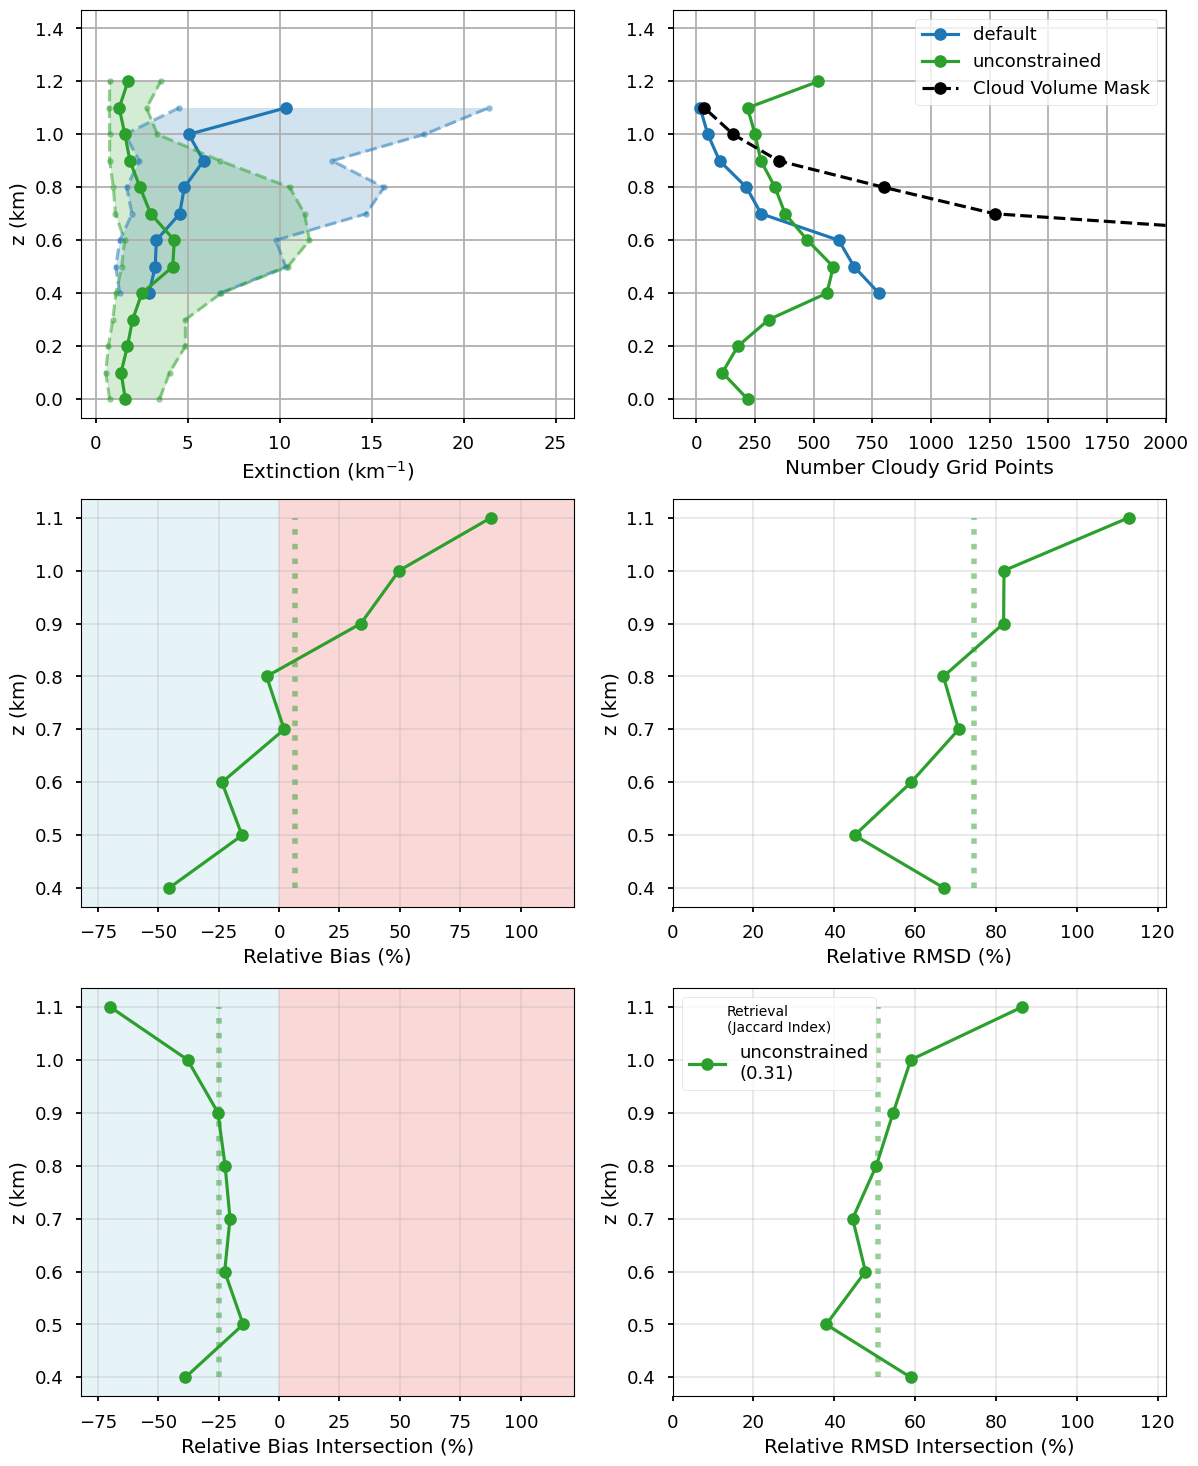

In [9]:
df = exset.to_dataframe(0.67, 'cloud', 'extinction')

cvm = exset.get_retrieval('default').cvm.cloud_volume_mask
cvm_vol = cvm.sum().data
cvm_nh = (cvm.integrate('z') > 0).sum().data

# Aggregate extinction at each z for each retrieval
l = 0.25
m = 0.5
h = 0.75
summary_quantiles = df.groupby(['retrieval_name', 'z'])['extinction'].quantile([l, m, h]).unstack().reset_index()
summary_counts = df.groupby(['retrieval_name', 'z'])['extinction'].agg(['count']).reset_index()
cvm = exset.get_retrieval('default').cvm.cloud_volume_mask.to_dataframe().reset_index()
cvm_counts = cvm[cvm['cloud_volume_mask'] == 1].groupby(['z'])['cloud_volume_mask'].agg(['count']).reset_index()

# sublist = ['default', '0p150']
# sublist = ['default', 'surf4p0']
# sublist = ['default', 'periodic']
# sublist = ['default', 'unconstrained', 'periodic', 'surf4p0', 'aod0p150', 'aod0p250']
sublist = ['default', 'unconstrained']
# sublist = ['default', 'ATM', 'ATP', 'CTM', 'CTP']
# sublist = ['unconstrained', 'ATM_unc', 'ATP_unc', 'CTM_unc', 'CTP_unc']
# sublist = ['unconstrained', 'CTM_unc', 'CTP_unc']
# sublist = ['unconstrained', 'ATM_unc', 'ATP_unc']
r2 = 'default'
# r2 = 'unconstrained'

f, axs = plt.subplots(3, 2, figsize=(14, 18), sharey=False, sharex=False)

# Extinction Vertical Profile
for retrieval_name in sublist:
    group = summary_quantiles[summary_quantiles['retrieval_name'] == retrieval_name].sort_values('z')
    c = cmap[retrieval_name]
    axs[0, 0].plot(group[m], group['z'], label=retrieval_name, marker='o', c=c)
    axs[0, 0].plot(group[l], group['z'], marker='.', ls='--', c=c, alpha=0.5)
    axs[0, 0].plot(group[h], group['z'], marker='.', ls='--', c=c, alpha=0.5)
    axs[0, 0].fill_betweenx(group['z'], group[l], group[h], alpha=0.2, color=c)
axs[0, 0].set_xlabel(r'Extinction (km$^{-1}$)')
axs[0, 0].set_ylabel('z (km)')
# ax[i, 0].legend()
# ax[i, 0].set_xscale('log')
axs[0, 0].grid()
axs[0, 0].set_xlim([-0.8, 26])

# CF by altitude (counts)
for retrieval_name in sublist:
    group = summary_counts[summary_counts['retrieval_name'] == retrieval_name].sort_values('z')
    axs[0, 1].plot(group['count'], group['z'], label=retrieval_name, marker='o', c=cmap[retrieval_name])
axs[0, 1].plot(cvm_counts['count'], cvm_counts['z'], label='Cloud Volume Mask', marker='o', c='k', ls='--')
axs[0, 1].set_xlabel('Number Cloudy Grid Points')
# ax[i, 1].set_ylabel('z')
axs[0, 1].legend()
axs[0, 1].grid()
axs[0, 1].set_xlim([-100, 2000])

# Metrics relative to default retreival
sublist.remove(r2)
fcns = ['Relative Bias (%)', 'Relative RMSD (%)', 'Relative Bias Intersection (%)', 'Relative RMSD Intersection (%)']
for (fn_name, ax) in zip(fcns, axs[1:,:].flatten()):
    # f, ax = plt.subplots(1, 1, figsize=(7,4))
    slice_df = stat_dict[fn_name]['dfCompareSlice']
    filtered_df = slice_df[slice_df['r2'] == r2]

    overall_df = stat_dict[fn_name]['dfCompare']

    for retrieval_name in sublist:
        Jac = stat_dict['Jaccard Index']['dfCompare'].loc[retrieval_name, r2]
        retrieval_data = filtered_df[filtered_df['r1'] == retrieval_name].sort_values('coordinate')
        ax.plot(retrieval_data['data'], retrieval_data['coordinate'], marker='o', label=f'{retrieval_name}\n({Jac:.2f})', c=cmap[retrieval_name])

        ax.vlines(overall_df.loc[retrieval_name, r2], 0.4, 1.1, color=cmap[retrieval_name], alpha=0.5, lw=4, ls='dotted')

    ax.set_xlabel(fn_name)
    ax.set_ylabel('z (km)')
    # ax.set_title(f'{fn_name}')
    # ax.legend()
    ax.grid(alpha=0.3)

axs[2,1].legend(title='Retrieval\n(Jaccard Index)')

axs[1,0].set_xlim([-82, 122])
axs[2,0].set_xlim([-82, 122])
axs[1,1].set_xlim([0, 122])
axs[2,1].set_xlim([0, 122])
# set_labels(axs.flatten())

cneg = 'lightcoral'
cpos = 'lightblue'
axs[1,0].axvspan(0, axs[1,0].get_xlim()[1], facecolor=cneg, alpha=0.3)
axs[1,0].axvspan(axs[1,0].get_xlim()[0], 0, facecolor=cpos, alpha=0.3)
axs[2,0].axvspan(0, axs[2,0].get_xlim()[1], facecolor=cneg, alpha=0.3)
axs[2,0].axvspan(axs[2,0].get_xlim()[0], 0, facecolor=cpos, alpha=0.3)

tmp_lim = [-0.07, 1.47]
axs[0,0].set_ylim(tmp_lim)
axs[0,1].set_ylim(tmp_lim)

# Stats by T

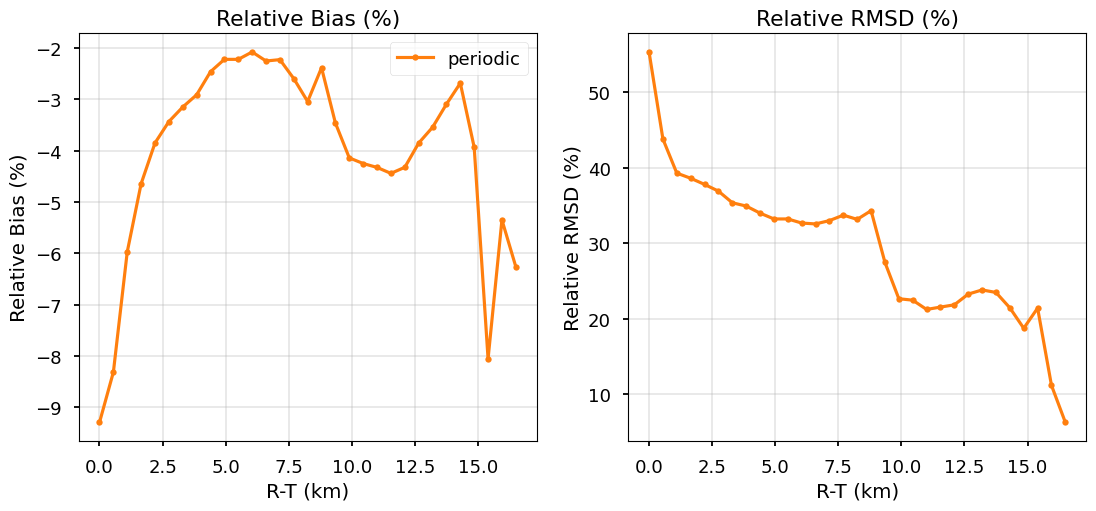

In [14]:
# sublist = ['0p150']
# sublist = ['surf4p0']
# sublist = ['periodic']
# sublist = ['unconstrained']
# sublist = ['unconstrained', 'surf4p0', 'aod0p150', 'aod0p250', 'periodic']
sublist = ['periodic']
# sublist = ['ATM', 'ATP', 'CTM', 'CTP']
r2 = 'default'

f, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=False, sharex=True)
# f.suptitle(f'R2 = {r2}')
f.subplots_adjust(hspace=0.3, top=0.925)

fcns = ['Relative Bias (%)', 'Relative RMSD (%)']
for (fn_name, ax) in zip(fcns, axs.flatten()):
    # f, ax = plt.subplots(1, 1, figsize=(7,4))
    slice_df = stat_dict[fn_name]['dfComapreTarget']
    filtered_df = slice_df[slice_df['r2'] == r2]

    for retrieval_name in sublist:
        retrieval_data = filtered_df[filtered_df['r1'] == retrieval_name].sort_values('coordinate')
        ax.plot(17.6 - retrieval_data['coordinate'], retrieval_data['data'], c=cmap[retrieval_name], marker='.', label=retrieval_name)
    
    ax.set_ylabel(fn_name)
    ax.set_xlabel('R-T (km)')
    ax.set_title(f'{fn_name}')
    # ax.legend()
    ax.grid(alpha=0.3)

axs[0].legend()
# set_labels(axs.flatten())